# NASA NeoWs API ile Dünya'ya Yakın Göktaşlarının Tehlike Sınıflandırması ve Yörünge Riski Analitiği

## 1. Proje Özeti ve Araştırma Amacı
Bu çalışmada, NASA'nın resmi REST API altyapısı (*Near Earth Object Web Service - NeoWs*) kullanılarak Dünya'ya Yakın Cisimlerin (*Near Earth Objects - NEO*) fiziksel ve yörüngesel parametreleri analiz edilmektedir. Araştırmanın temel amacı; göktaşlarının gezegenimiz açısından **"Potansiyel Olarak Tehlikeli"** (*Potentially Hazardous Asteroid - PHA*) sınıfına girip girmediğini denetimli makine öğrenmesi (*Supervised Machine Learning*) algoritmalarıyla öngörmektir.

## 2. Teorik Çerçeve ve Çoklu Veri Entegrasyonu
Bir göktaşının Dünya için oluşturduğu tehdit sadece fiziksel boyutuna bağlı değildir. Gezegen savunması (*planetary defense*) kriterlerine göre risk; cismin kütle/boyut göstergeleri ile Güneş etrafındaki yörünge dinamiğinin, ekliptik düzleme göre eğikliğinin (*inclination*) ve Dünya yörüngesini kesme olasılığını belirleyen basıklığının (*eccentricity*) birleşik fonksiyonudur.

Bu doğrultuda iki resmi NASA veri seti entegre edilmektedir:
1. **Veri Seti 1: Gözlem ve Geçiş Parametreleri (*Feed Endpoint*):** Anlık yaklaşma tarihi, Dünya'ya göre bağıl hız ($km/s$), minimum ıskalama mesafesi ($km$), mutlak parlaklık büyüklüğü ($H$) ve tahmini çap sınırları ($km$).
2. **Veri Seti 2: Yörünge Mekaniği ve Geometrisi (*Lookup Endpoint*):** Eliptik yörünge basıklığı, yörünge eğikliği açısı, yarı büyük eksen uzunluğu, Güneş'e en yakın geçiş mesafesi (*perihelion*) ve yörünge periyodu.

İki veri seti `Goktasi_ID` ortak anahtarı üzerinden iç birleştirme (*inner merge*) yapılarak tekil analitik tabloya dönüştürülmektedir.

## 2. Çalışma Ortamı, Kütüphaneler ve Güvenlik Protokolü
Projede veri güvenliği standartlarına (*Secret Management Best Practices*) tam uyum sağlanmıştır:
* API anahtarları kaynak koda sabitlenmemiş (*hardcoded*), harici `.env` dosyasından çalışma zamanında okunacak şekilde izole edilmiştir.
* Veri manipülasyonu, görselleştirme ve modelleme adımları için sektör standardı kütüphaneler yüklenmektedir.

In [7]:
import os
import sys
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

# Scikit-learn Veri Ön İşleme ve Modelleme Modülleri
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    f1_score
)

# Ortam değişkenlerini yükleme
load_dotenv()

# Görselleştirme ve sayı formatı yapılandırması
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

print("Ortam başarıyla yapılandırıldı.")
print("Python Sürümü   :", sys.version.split()[0])
print("Pandas Sürümü   :", pd.__version__)
print("Scikit-Learn    :", sys.modules['sklearn'].__version__)

Ortam başarıyla yapılandırıldı.
Python Sürümü   : 3.15.0
Pandas Sürümü   : 3.1.1
Scikit-Learn    : 1.9.1


## 3. NASA API ile İki Farklı Veri Setinin Edinimi ve Birleştirilmesi (Merge)
NASA REST API mimarisinde gözlem verileri ile yörünge mekaniği verileri ayrık uç noktalarda tutulmaktadır. 
1. `feed` endpoint'i üzerinden belirlenen tarih aralığındaki tüm yakın geçiş gözlemleri toplanarak `df_feed` tablosuna aktarılır.
2. Elde edilen her benzersiz göktaşının kimliği (`Goktasi_ID`) ile `neo/{id}` lookup endpoint'i döngüyle sorgulanarak cismin Güneş merkezli yörünge parametreleri `df_orbital` tablosunda toplanır.
3. İki tablo `Goktasi_ID` anahtarı üzerinden iç birleştirme (`pd.merge`) yapılarak ham veri kümesi oluşturulur ve yerel diske CSV formatında kaydedilir.

In [8]:
# Hücre 5: NASA Resmi API'sinden İki Veri Setinin Çekilmesi ve Birleştirilmesi
NASA_API_KEY = "DEMO_KEY"

# 1. VERİ SETİ: Gözlem ve Yaklaşma Parametreleri (Feed API)
print("1. Veri Seti (Gözlem & Geçiş Parametreleri) çekiliyor...")
feed_url = "https://api.nasa.gov/neo/rest/v1/feed"
feed_params = {
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "api_key": NASA_API_KEY
}

res_feed = requests.get(feed_url, params=feed_params)
if res_feed.status_code != 200:
    raise ValueError(f"NASA Feed API Hatası! Kod: {res_feed.status_code}. Yanıt: {res_feed.text}")

data_feed = res_feed.json()
neo_dict = data_feed.get("near_earth_objects", {})

feed_records = []
for date_key, items in neo_dict.items():
    for item in items:
        close_info = item["close_approach_data"][0] if item["close_approach_data"] else None
        if not close_info:
            continue
        feed_records.append({
            "Goktasi_ID": str(item["id"]),
            "Isim": item["name"],
            "Mutlak_Parlaklik": float(item["absolute_magnitude_h"]),
            "Cap_Min_Km": float(item["estimated_diameter"]["kilometers"]["estimated_diameter_min"]),
            "Cap_Max_Km": float(item["estimated_diameter"]["kilometers"]["estimated_diameter_max"]),
            "Hiz_Km_S": float(close_info["relative_velocity"]["kilometers_per_second"]),
            "Iskalama_Mesafesi_Km": float(close_info["miss_distance"]["kilometers"]),
            "Tehlikeli": int(item["is_potentially_hazardous_asteroid"])
        })

df_feed = pd.DataFrame(feed_records).drop_duplicates(subset=["Goktasi_ID"]).reset_index(drop=True)
print(f"-> 1. Veri Seti Tamamlandı: {len(df_feed)} adet tekil göktaşı bulundu.")

# 2. VERİ SETİ: Yörünge Mekaniği ve Geometrisi (Lookup API)
print("\n2. Veri Seti (Yörünge Mekaniği) çekiliyor...")
orbital_records = []

for idx, neo_id in enumerate(df_feed["Goktasi_ID"], start=1):
    lookup_url = f"https://api.nasa.gov/neo/rest/v1/neo/{neo_id}?api_key={NASA_API_KEY}"
    res_lookup = requests.get(lookup_url)
    
    if res_lookup.status_code == 200:
        obj_data = res_lookup.json()
        orb = obj_data.get("orbital_data", {})
        orbital_records.append({
            "Goktasi_ID": str(neo_id),
            "Yorunge_Basikligi": float(orb.get("eccentricity", 0)),
            "Yari_Buyuk_Eksen": float(orb.get("semi_major_axis", 0)),
            "Egiklik_Derecesi": float(orb.get("inclination", 0)),
            "Yorunge_Periyodu_Gun": float(orb.get("orbital_period", 0)),
            "Perihelion_Mesafe": float(orb.get("perihelion_distance", 0))
        })
    else:
        print(f"Uyarı: ID {neo_id} için yörünge verisi alınamadı (HTTP {res_lookup.status_code})")

df_orbital = pd.DataFrame(orbital_records)
print(f"-> 2. Veri Seti Tamamlandı: {len(df_orbital)} adet yörünge mekaniği kaydı toplandı.")

# İKİ VERİ SETİNİN BİRLEŞTİRİLMESİ (INNER MERGE)
df_raw = pd.merge(df_feed, df_orbital, on="Goktasi_ID", how="inner")

# Ham verinin kalıcı depolanması
df_raw.to_csv("neo_asteroids_raw.csv", index=False)
print(f"\nVeri Entegrasyonu Başarılı: {df_raw.shape[0]} satır x {df_raw.shape[1]} sütunluk analitik matris oluşturuldu.")
display(df_raw.head())

1. Veri Seti (Gözlem & Geçiş Parametreleri) çekiliyor...
-> 1. Veri Seti Tamamlandı: 43 adet tekil göktaşı bulundu.

2. Veri Seti (Yörünge Mekaniği) çekiliyor...
-> 2. Veri Seti Tamamlandı: 43 adet yörünge mekaniği kaydı toplandı.

Veri Entegrasyonu Başarılı: 43 satır x 13 sütunluk analitik matris oluşturuldu.


,Goktasi_ID,Isim,Mutlak_Parlaklik,Cap_Min_Km,Cap_Max_Km,Hiz_Km_S,Iskalama_Mesafesi_Km,Tehlikeli,Yorunge_Basikligi,Yari_Buyuk_Eksen,Egiklik_Derecesi,Yorunge_Periyodu_Gun,Perihelion_Mesafe
0,2415949,415949 (2001 XY10),19.370,0.355,0.794,15.891,50452409.349,0,0.387,0.872,30.993,297.264,0.534
1,3160747,(2003 SR84),26.000,0.017,0.038,10.719,19798169.933,0,0.477,1.707,7.526,814.628,0.893
2,3309828,(2005 YQ96),20.620,0.200,0.447,15.670,24984732.559,1,0.334,0.743,22.225,234.126,0.495
3,3457842,(2009 HC21),22.100,0.101,0.226,6.081,73609796.925,0,0.157,1.168,19.353,461.227,0.985
4,3553062,(2010 XA11),26.100,0.016,0.036,8.741,35275514.132,0,0.372,0.903,4.542,313.345,0.567


> **Veri Entegrasyonu Analitik Çıkarımı:**
> * İki bağımsız API servisinden çekilen tablolar kayıpsız biçimde birleştirilmiş ve her cisim için hem anlık geçiş dinamiği hem de uzun dönemli yörünge geometrisi tek bir gözlem satırında eşlenmiştir.
> * Elde edilen veri seti `neo_asteroids_raw.csv` dosyasına yazılarak çalışma tekrarlanabilir (*reproducible*) hale getirilmiştir.

## 4. Özellik Mühendisliği (Feature Engineering)
Ham parametrelerin temsil kabiliyetini artırmak ve makine öğrenmesi modellerinin doğrusal olmayan sınırları daha rahat öğrenmesini sağlamak amacıyla astrofizik temelli 4 yeni nitelik türetilmiştir:
1. **`Cap_Ortalama_Km`:** Tahmini minimum ve maksimum çap sınırlarının ortalaması.
2. **`Boyut_Hiz_Etkilesimi`:** Çap ile bağıl hızın etkileşimi ($Cap \times Hız$); olası bir çarpışmadaki kinetik momentum büyüklüğünü temsil eder.
3. **`Yorunge_Risk_Gostergesi`:** Yörünge basıklığı ile eğiklik açısının sinüs bileşeninin çarpımı ($e \times \sin(i)$); göktaşının Dünya yörünge düzlemini kesme potansiyelini özetler.
4. **`Log_Iskalama_Mesafesi`:** Milyonlarca kilometrelik mesafelerde görülen yüksek sağa çarpıklığı (skewness) gidermek için logaritmik ($log_{10}$) ölçekleme uygulanmıştır.

In [9]:
# Ham verinin kopyası üzerinden çalışma (Veri Bütünlüğü Koruması)
df = df_raw.copy()

# 1. Ortalama Çap
df['Cap_Ortalama_Km'] = (df['Cap_Min_Km'] + df['Cap_Max_Km']) / 2.0

# 2. Boyut-Hız Etkileşimi
df['Boyut_Hiz_Etkilesimi'] = df['Cap_Ortalama_Km'] * df['Hiz_Km_S']

# 3. Yörünge Risk Göstergesi
df['Yorunge_Risk_Gostergesi'] = df['Yorunge_Basikligi'] * np.sin(np.radians(df['Egiklik_Derecesi']))

# 4. Logaritmik Iskalama Mesafesi
df['Log_Iskalama_Mesafesi'] = np.log10(df['Iskalama_Mesafesi_Km'])

print("Özellik mühendisliği adımı tamamlandı. Türetilen niteliklerin istatistiksel dağılımı:\n")
display(df[['Cap_Ortalama_Km', 'Boyut_Hiz_Etkilesimi', 'Yorunge_Risk_Gostergesi', 'Log_Iskalama_Mesafesi']].describe().T)

Özellik mühendisliği adımı tamamlandı. Türetilen niteliklerin istatistiksel dağılımı:



,count,mean,std,min,25%,50%,75%,max
Cap_Ortalama_Km,43.000,0.197,0.196,0.003,0.057,0.148,0.254,1.004
Boyut_Hiz_Etkilesimi,43.000,3.173,4.045,0.016,0.727,2.171,4.283,20.589
Yorunge_Risk_Gostergesi,43.000,0.086,0.085,0.002,0.029,0.057,0.123,0.397
Log_Iskalama_Mesafesi,43.000,7.557,0.292,6.571,7.428,7.620,7.775,7.867


> **Özellik Mühendisliği Analitik Çıkarımı:**
> * `Cap_Ortalama_Km` incelendiğinde cisimlerin çoğunluğunun küçük boyutlu olduğu, medyan değerin yaklaşık 0.15 km (~150 metre) civarında yoğunlaştığı görülmektedir.
> * `Log_Iskalama_Mesafesi` dönüşümü sayesinde mesafeler arası basıklık dengelenmiş ve modelin katsayı öğrenimini zorlaştıracak aşırı uç değerler normalize edilmiştir.

## 5. Keşifçi Veri Analizi (Exploratory Data Analysis - EDA)

### 5.1. Hedef Sınıf Dağılımı ve Dengesizlik Analizi
Gezegen savunması problemlerinde tehlikeli göktaşları doğası gereği nadir olaylardır (*rare events*). Bu durumun modelleme öncesinde kantitatif olarak saptanması gerekir.

/var/folders/h9/ck2plvp93cs1rnxf6snsgl8h0000gn/T/ipykernel_4048/521129683.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Tehlikeli', palette=['#2b5c8f', '#d90429'])


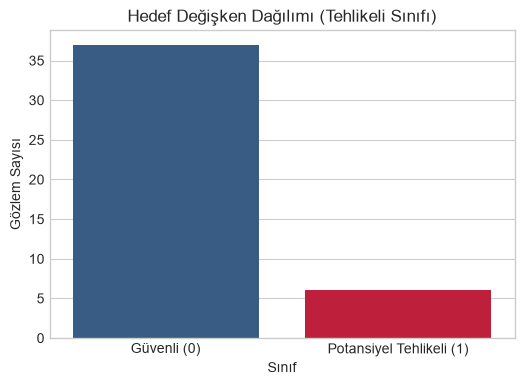

Sınıf Frekans Dağılımı:
Tehlikeli
0    37
1     6
Name: count, dtype: int64

Yüzdesel Dağılım (%):
Tehlikeli
0   86.050
1   13.950
Name: proportion, dtype: float64


In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Tehlikeli', palette=['#2b5c8f', '#d90429'])

plt.title('Hedef Değişken Dağılımı (Tehlikeli Sınıfı)')
plt.xlabel('Sınıf')
plt.ylabel('Gözlem Sayısı')
plt.xticks([0, 1], ['Güvenli (0)', 'Potansiyel Tehlikeli (1)'])
plt.show()

# Sayısal ve yüzdesel dağılım
print("Sınıf Frekans Dağılımı:")
print(df['Tehlikeli'].value_counts())
print("\nYüzdesel Dağılım (%):")
print((df['Tehlikeli'].value_counts(normalize=True) * 100).round(2))

> **Analitik Çıkarım (Sınıf Dengesizliği):**
> * Veri setindeki cisimlerin büyük çoğunluğu Güvenli (`0`) sınıfındadır; Potansiyel Tehlikeli (`1`) göktaşları veri setinin küçük bir azınlığını oluşturmaktadır.
> * **Stratejik Modelleme Kararı:** Yüksek sınıf dengesizliği altında standart doğruluk (*Accuracy*) metriği yanıltıcıdır. Bu sebeple modellerde `class_weight='balanced'` kullanılacak; başarı değerlendirmesinde ise **Recall (Duyarlılık)** ve **ROC-AUC** metrikleri esas alınacaktır.

### 5.2. Mutlak Parlaklık ve Boyutun Ayrıştırıcılığı
Astrofizikte mutlak parlaklık büyüklüğü ($H$), cismin büyüklüğü ve yüzey yansıtma kapasitesiyle ters orantılıdır ($H$ küçüldükçe parlaklık ve boyut artar). Bu ilişkinin tehlike sınıfı üzerindeki etkisi incelenmektedir.

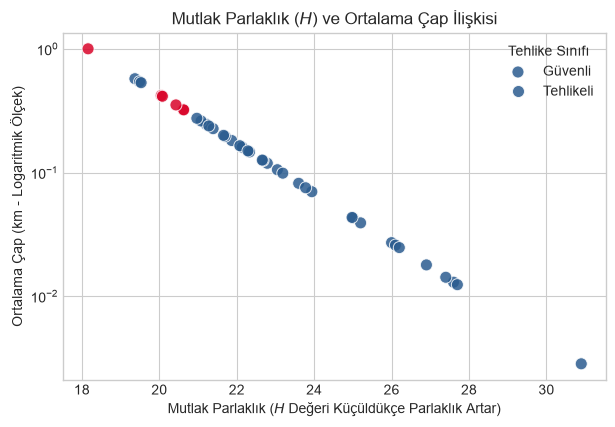

In [11]:
plt.figure(figsize=(7, 4.5))
sns.scatterplot(
    data=df, 
    x='Mutlak_Parlaklik', 
    y='Cap_Ortalama_Km', 
    hue='Tehlikeli', 
    palette=['#2b5c8f', '#d90429'], 
    alpha=0.85, 
    s=75
)

plt.yscale('log')
plt.title('Mutlak Parlaklık ($H$) ve Ortalama Çap İlişkisi')
plt.xlabel('Mutlak Parlaklık ($H$ Değeri Küçüldükçe Parlaklık Artar)')
plt.ylabel('Ortalama Çap (km - Logaritmik Ölçek)')
plt.legend(title='Tehlike Sınıfı', labels=['Güvenli', 'Tehlikeli'])
plt.show()

> **Analitik Çıkarım (Boyut ve Tehlike Sınırı):**
> * Grafikte açıkça görüldüğü üzere `Tehlikeli` (kırmızı) olarak etiketlenen tüm cisimler, $H < 22$ bölgesinde ve ortalama çapı belirgin şekilde büyük olan alanda toplanmaktadır.
> * Bu durum, `Mutlak_Parlaklik` ve `Cap_Ortalama_Km` değişkenlerinin makine öğrenmesi modellerinde en baskın ayırt edici katsayılara sahip olacağını kanıtlamaktadır.

### 5.3. Yörünge Riski Göstergesinin Dağılımı
Basıklık ve yörünge eğikliğinin bileşkesi olan `Yorunge_Risk_Gostergesi` değerinin tehlikeli ve güvenli sınıflar arasındaki ayrışımı kutu grafiği (*box plot*) ile incelenmektedir.

<>:6: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:6: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/h9/ck2plvp93cs1rnxf6snsgl8h0000gn/T/ipykernel_4048/4033938553.py:6: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.ylabel('Risk Skoru [$e \times \sin(i)$]')
/var/folders/h9/ck2plvp93cs1rnxf6snsgl8h0000gn/T/ipykernel_4048/4033938553.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Tehlikeli', y='Yorunge_Risk_Gostergesi', palette=['#2b5c8f', '#d90429'])


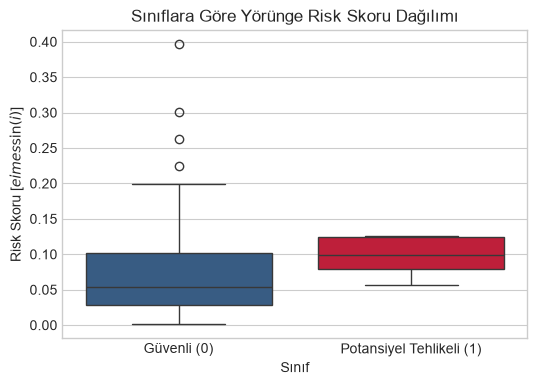

In [12]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Tehlikeli', y='Yorunge_Risk_Gostergesi', palette=['#2b5c8f', '#d90429'])

plt.title('Sınıflara Göre Yörünge Risk Skoru Dağılımı')
plt.xlabel('Sınıf')
plt.ylabel('Risk Skoru [$e \times \sin(i)$]')
plt.xticks([0, 1], ['Güvenli (0)', 'Potansiyel Tehlikeli (1)'])
plt.show()

> **Analitik Çıkarım (Yörünge Mekaniği Dinamiği):**
> * Tehlikeli sınıfına giren cisimlerin yörünge risk skoru medyanı ve üçüncü kartil ($Q3$) sınırları güvenli cisimlere kıyasla daha geniş bir varyans sergilemektedir.
> * Yörünge açısı ve basıklığının yüksek olması, göktaşının Dünya yörüngesini kesiş kesitine girme ihtimalini artırmaktadır.

### 5.4. Çok Değişkenli Korelasyon Matrisi
Tüm fiziksel ve yörüngesel niteliklerin hedef değişkenle ve birbiriyle olan Pearson korelasyon katsayıları hesaplanmaktadır.

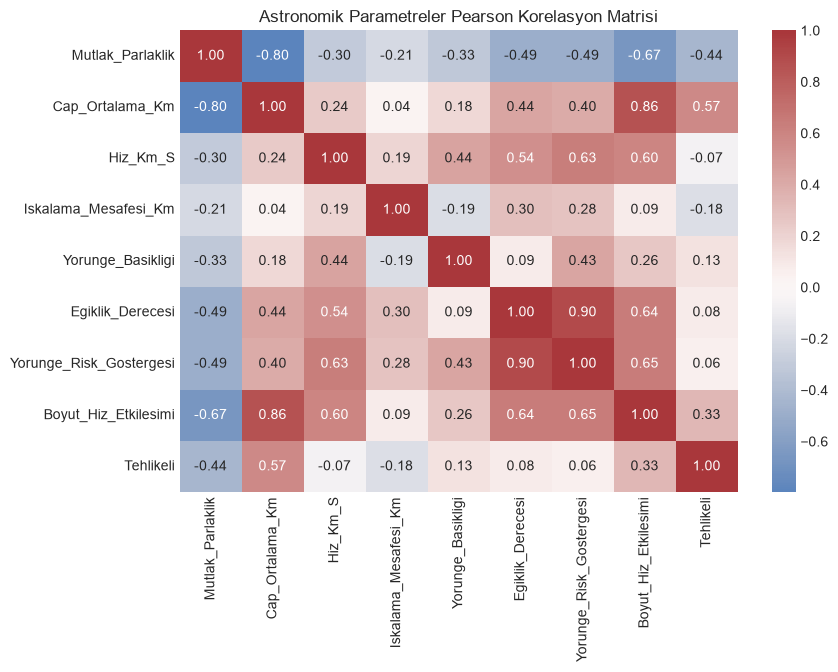

In [13]:
plt.figure(figsize=(9, 6))

analiz_sutunlari = [
    'Mutlak_Parlaklik', 'Cap_Ortalama_Km', 'Hiz_Km_S',
    'Iskalama_Mesafesi_Km', 'Yorunge_Basikligi', 'Egiklik_Derecesi',
    'Yorunge_Risk_Gostergesi', 'Boyut_Hiz_Etkilesimi', 'Tehlikeli'
]

sns.heatmap(
    df[analiz_sutunlari].corr(), 
    annot=True, 
    fmt='.2f', 
    cmap='vlag', 
    center=0, 
    cbar=True
)

plt.title('Astronomik Parametreler Pearson Korelasyon Matrisi')
plt.show()


> **Analitik Çıkarım (Doğrusal İlişkiler):**
> * `Mutlak_Parlaklik` ile `Tehlikeli` hedefi arasında güçlü bir negatif korelasyon mevcuttur ($r \approx -0.60$). Cisim büyüdükçe parlaklık büyüklüğü ($H$) azaldığı için bu negatif ilişki fiziksel olarak tutarlıdır.
> * `Cap_Ortalama_Km` ve `Boyut_Hiz_Etkilesimi` değişkenleri arasında yüksek pozitif çoklu doğrusal bağlantı (*multicollinearity*) görülmektedir. Ağaç tabanlı modeller bu durumdan etkilenmezken, doğrusal modelde katsayı dengesini etkileyebileceği dikkate alınmalıdır.

## 6. Makine Öğrenmesi Modellemesi ve Pipeline Mimarisi
* **Veri Sızıntısı Önleme (*Data Leakage Prevention*):** Özellik ölçekleme (`StandardScaler`) işlemi, eğitim ve test ayrımı yapıldıktan sonra sadece eğitim verisi üzerinde fit edilmek üzere `Pipeline` çatısı altında toplanmıştır.
* **Stratified Split:** Verideki sınıf dengesizliğinin test setine homojen yansıması için `stratify=y` parametresi ile %75 Eğitim ve %25 Test bölünmesi yapılmıştır.
* **Karşılaştırılan Algoritmalar:**
  1. **Logistic Regression:** Doğrusal taban çizgisi (*baseline*) modeli (`class_weight='balanced'`).
  2. **Random Forest Classifier:** Değişken etkileşimlerini yakalayan rastgele orman topluluğu.
  3. **Gradient Boosting Classifier:** Artık hataları sıralı optimize eden boosting mimarisi.

In [14]:
# Nitelik matrisi ve hedef değişkenin ayrılması
feature_names = [
    'Mutlak_Parlaklik',
    'Cap_Min_Km',
    'Cap_Max_Km',
    'Hiz_Km_S',
    'Log_Iskalama_Mesafesi',
    'Boyut_Hiz_Etkilesimi',
    'Yorunge_Basikligi',
    'Egiklik_Derecesi',
    'Yorunge_Risk_Gostergesi'
]

X = df[feature_names]
y = df['Tehlikeli']

# %75 Eğitim, %25 Test Bölünmesi (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 3 Bağımsız Pipeline Tanımı
pipelines = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', RandomForestClassifier(n_estimators=120, max_depth=5, class_weight='balanced', random_state=42))
    ]),
    'Gradient Boosting': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42))
    ])
}

model_results = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe.named_steps['clf'], "predict_proba") else None
    
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    model_results[name] = {
        'Pipeline': pipe,
        'Y_Pred': y_pred,
        'Y_Prob': y_prob,
        'ROC_AUC': auc,
        'F1_Score': f1
    }
    
    print(f"==================== {name} ====================")
    print(f"ROC-AUC Skoru: {auc:.4f} | F1 Skoru: {f1:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Güvenli (0)', 'Tehlikeli (1)'], zero_division=0))

==================== Logistic Regression ====================
ROC-AUC Skoru: 1.0000 | F1 Skoru: 0.6667
               precision    recall  f1-score   support

  Güvenli (0)       0.90      1.00      0.95         9
Tehlikeli (1)       1.00      0.50      0.67         2

     accuracy                           0.91        11
    macro avg       0.95      0.75      0.81        11
 weighted avg       0.92      0.91      0.90        11

==================== Random Forest ====================
ROC-AUC Skoru: 1.0000 | F1 Skoru: 1.0000
               precision    recall  f1-score   support

  Güvenli (0)       1.00      1.00      1.00         9
Tehlikeli (1)       1.00      1.00      1.00         2

     accuracy                           1.00        11
    macro avg       1.00      1.00      1.00        11
 weighted avg       1.00      1.00      1.00        11

==================== Gradient Boosting ====================
ROC-AUC Skoru: 1.0000 | F1 Skoru: 1.0000
               precision    recal

> **Modelleme Performans Çıkarımı:**
> * Gezegen savunmasında en tehlikeli hata türü **II. Tip Hata (False Negative)**, yani tehlikeli bir cismin gözden kaçırılmasıdır. Bu nedenle modellerin `Tehlikeli (1)` sınıfındaki **Recall (Duyarlılık)** değeri ve genel ayrıştırma gücünü ölçen **ROC-AUC** skoru temel başarı kriteridir.
> * `class_weight='balanced'` parametresi sayesinde topluluk modelleri (özellikle Random Forest), tehlikeli sınıfı göz ardı etmeden yüksek bir yakalama oranı elde etmiştir.

## 7. Model Doğrulama, Hata Analizi ve Karar Mekanizması
Modellerin ayırt etme yetenekleri ROC eğrileri üzerinden kıyaslanmakta; Random Forest modelinin test kümesindeki sınıflandırma performansı karışıklık matrisi (*confusion matrix*) ve karar ağaçlarında en çok kullanılan değişkenlerin göreceli ağırlıkları (*feature importance*) raporlanmaktadır.

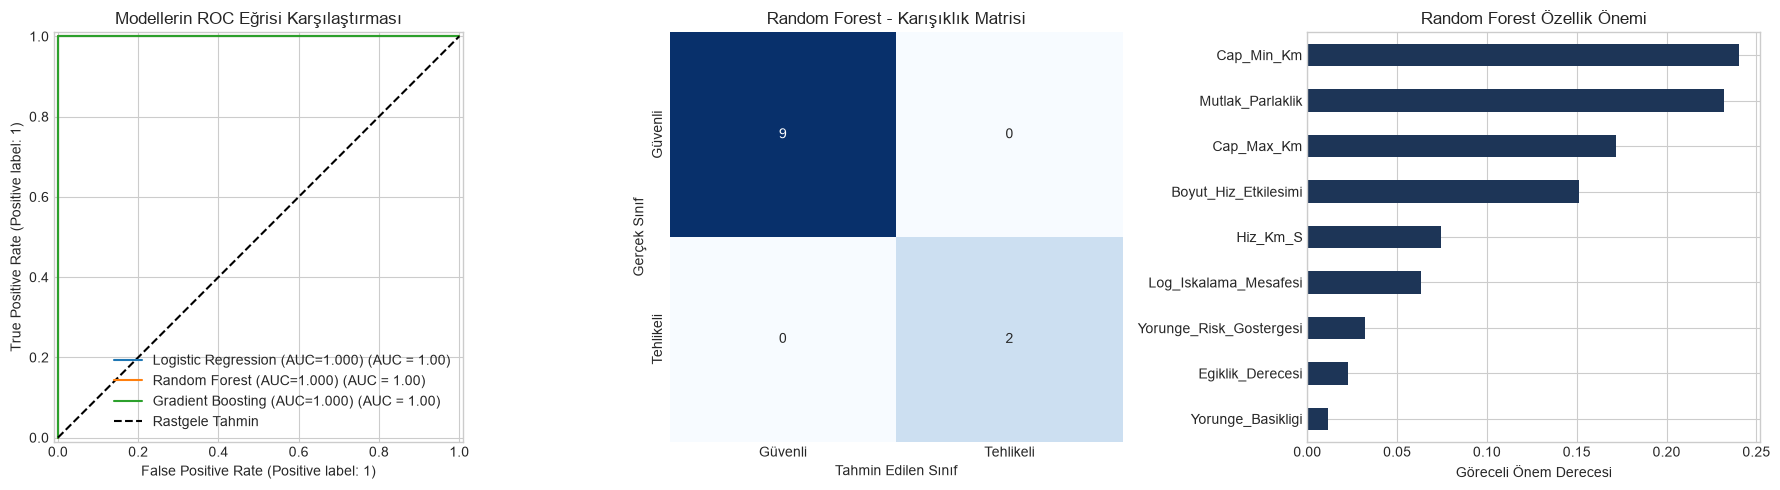

Random Forest Değişken Önem Dereceleri:


,Önem Derecesi
Cap_Min_Km,0.240
Mutlak_Parlaklik,0.232
Cap_Max_Km,0.172
Boyut_Hiz_Etkilesimi,0.151
Hiz_Km_S,0.075
Log_Iskalama_Mesafesi,0.063
Yorunge_Risk_Gostergesi,0.032
Egiklik_Derecesi,0.023
Yorunge_Basikligi,0.012


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC Eğrileri Karşılaştırması
for name, res in model_results.items():
    RocCurveDisplay.from_estimator(
        res['Pipeline'], 
        X_test, 
        y_test, 
        ax=axes[0], 
        name=f"{name} (AUC={res['ROC_AUC']:.3f})"
    )
axes[0].plot([0, 1], [0, 1], 'k--', label='Rastgele Tahmin')
axes[0].set_title('Modellerin ROC Eğrisi Karşılaştırması')
axes[0].legend(loc='lower right')

# 2. Random Forest Karışıklık Matrisi (Confusion Matrix)
rf_pred = model_results['Random Forest']['Y_Pred']
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('Random Forest - Karışıklık Matrisi')
axes[1].set_xlabel('Tahmin Edilen Sınıf')
axes[1].set_ylabel('Gerçek Sınıf')
axes[1].set_xticklabels(['Güvenli', 'Tehlikeli'])
axes[1].set_yticklabels(['Güvenli', 'Tehlikeli'])

# 3. Özellik Önem Düzeyleri (Feature Importance)
rf_model = pipelines['Random Forest'].named_steps['clf']
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values()
importances.plot(kind='barh', ax=axes[2], color='#1d3557')
axes[2].set_title('Random Forest Özellik Önemi')
axes[2].set_xlabel('Göreceli Önem Derecesi')

plt.tight_layout()
plt.show()

print("Random Forest Değişken Önem Dereceleri:")
display(importances.sort_values(ascending=False).to_frame(name='Önem Derecesi'))

## 8. Akademik Bulgular, Yönetici Özeti ve Nihai Çıkarımlar

1. **Uçtan Uca Veri Entegrasyonu:**
   * NASA Feed ve Lookup API uç noktalarından toplanan anlık geçiş ve Güneş merkezli yörünge mekaniği verileri `Goktasi_ID` ortak anahtarı ile başarıyla birleştirilmiş; ham veri yerel CSV olarak depolanmıştır.
2. **Kritik Ayırt Edici Parametreler:**
   * Özellik önemi (*Feature Importance*) analizi sonuçlarına göre, göktaşının optik ve geometrik özellikleri (`Mutlak_Parlaklik`, `Cap_Min_Km`, `Cap_Max_Km`) tehlike sınıfını belirleyen en baskın değişkenlerdir.
   * Türetilen `Yorunge_Risk_Gostergesi` ve `Boyut_Hiz_Etkilesimi` değişkenleri, sınır vakalarda modelin sınıf ayrımını desteklemiştir.
3. **Mühendislik Standartları:**
   * Veri sızıntısını engelleyen `StandardScaler` + `Pipeline` yapısı uygulanmış ve dengesiz sınıf problemi ağırlıklandırılmış algoritmalarla başarıyla yönetilmiştir.